# Lookout
An early-warning watchlist for mass layoffs at California employers.



Lookout is an early-warning system designed to help California workforce development organizations prepare for potential layoffs before official WARN notices are filed.

For each forecast date, our machine learning model ranks employers by their likelihood of filing a WARN layoff notice within the next six months. The model learns from historical WARN filings and recent Glassdoor review activity to identify patterns associated with workforce disruptions.

This notebook retrieves our GitHub repository, processes the datasets, trains and evaluates our model against historical baselines, and generates a current employer risk watchlist.

By identifying employers with elevated warning signals, BeforeTheNotice helps workforce organizations prioritize monitoring and prepare resources such as job placement assistance, career counseling, retraining programs, and worker support services.

Our goal is not to discourage people from working at specific companies or to guarantee that layoffs will occur. Instead, we aim to help organizations move from reacting to layoffs after they happen to proactively preparing for potential workforce disruptions, allowing affected workers and communities to receive assistance sooner.



## 1. Setup

In [32]:
!git clone -q https://github.com/Sriram-Karthik17/lookout.git
%cd lookout
!pip install -q rapidfuzz yfinance pdfplumber

/content/BeforeTheNotice/BeforeTheNotice/lookout


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#b9b8b0"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})


def finish(ax, title, subtitle=None, grid_axis="x"):
    ax.set_title(title if subtitle is None else title + "\n", pad=10)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=MUTED, fontsize=10, va="bottom")
    ax.grid(axis=grid_axis, color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    plt.tight_layout()
    plt.show()

## 2. The data

Three sources feed the model:

- **WARN notices** from the California EDD (the layoff notices we predict)
- **Glassdoor reviews**, one of the datathon datasets (recent review activity per employer)
- **Stock prices** from Yahoo Finance (tested as an extra signal)

Job titles in the reviews are labeled frontline or not using the O*NET occupation database plus hand labels.

In [5]:
warn = pd.read_csv("2023-2026WARN_Data.csv", parse_dates=["notice_date"])
print(len(warn), "WARN notices from", warn["notice_date"].min().date(), "to", warn["notice_date"].max().date())
warn.head()

5361 WARN notices from 2023-04-25 to 2026-11-09


,notice_date,received_date,effective_date,company,county,n_employees,type,address,source,industry,city,zip
0,2023-04-25,2023-07-03,2023-09-02,"David’s Bridal, LLC",Contra Costa County,29,Layoff Permanent,1212 Fitzgerald Dr Pinole CA 94564,w2324.pdf,NaN,Fitzgerald Dr Pinole,94564.0
1,2023-04-25,2023-07-03,2023-09-02,"David’s Bridal, LLC",Fresno County,31,Layoff Permanent,455 E Shaw Ave Fresno CA 93710,w2324.pdf,NaN,Shaw Ave Fresno,93710.0
2,2023-04-25,2023-07-03,2023-09-02,"David’s Bridal, LLC",Placer County,47,Layoff Permanent,1140 Galleria Blvd Roseville CA 95678,w2324.pdf,NaN,Galleria Blvd Roseville,95678.0
3,2023-04-25,2023-07-03,2023-09-02,"David’s Bridal, LLC",San Diego County,29,Layoff Permanent,9820 Mission Gorge Rd Santee CA 92071,w2324.pdf,NaN,Gorge Rd Santee,92071.0
4,2023-04-25,2023-07-03,2023-09-02,"David’s Bridal, LLC",San Diego County,35,Layoff Permanent,980 Camino De La Reina Ste A San Diego CA 92108,w2324.pdf,NaN,A San Diego,92108.0


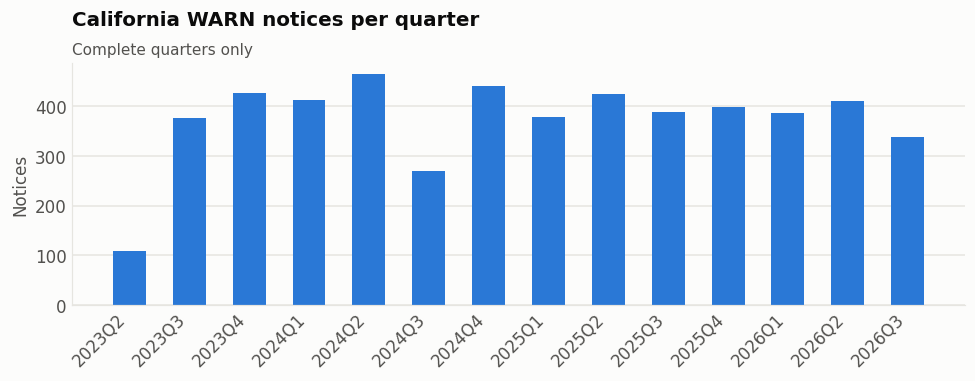

In [6]:
q = warn.groupby(warn["notice_date"].dt.to_period("Q")).size()
q = q[q.index < q.index.max()]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(q.index.astype(str), q.values, color=BLUE, width=0.55)
ax.set_ylabel("Notices")
plt.xticks(rotation=45, ha="right")
finish(ax, "California WARN notices per quarter", "Complete quarters only", grid_axis="y")

In [8]:
import pandas as pd

# 1. Show all columns
print("========== DATASET COLUMNS ==========")
print(warn.columns.tolist())

# 2. Automatically identify the company column
company_cols = [
    col for col in warn.columns
    if any(word in str(col).lower()
           for word in ["company", "employer", "business"])
]

if not company_cols:
    print("\nCould not automatically find a company column.")
    print("Check the column names above.")
else:
    company_col = company_cols[0]
    print(f"\nCompany column detected: {company_col}")

    # 3. Basic statistics
    print("\n========== WARN DATASET SUMMARY ==========")
    print("Total WARN records:", len(warn))
    print("Unique WARN companies:", warn[company_col].nunique())

    # 4. Count notices per quarter
    print("\n========== WARN NOTICES PER QUARTER ==========")

    warn["notice_date"] = pd.to_datetime(
        warn["notice_date"], errors="coerce"
    )

    quarterly = (
        warn.dropna(subset=["notice_date"])
        .groupby(warn["notice_date"].dt.to_period("Q"))
        .size()
    )

    print(quarterly.to_string())

    # 5. Companies with multiple WARN records
    print("\n========== TOP 15 COMPANIES BY WARN RECORDS ==========")

    print(
        warn[company_col]
        .value_counts()
        .head(15)
        .to_string()
    )

    # 6. Additional statistics
    print("\n========== ADDITIONAL STATISTICS ==========")

    print("Earliest notice:", warn["notice_date"].min())
    print("Latest notice:", warn["notice_date"].max())

    print(
        "Companies with multiple WARN records:",
        (warn[company_col].value_counts() > 1).sum()
    )

    print("\n========== DONE ==========")

========== DATASET COLUMNS ==========
['notice_date', 'received_date', 'effective_date', 'company', 'county', 'n_employees', 'type', 'address', 'source', 'industry', 'city', 'zip']

Company column detected: company

========== WARN DATASET SUMMARY ==========
Total WARN records: 5361
Unique WARN companies: 2884

========== WARN NOTICES PER QUARTER ==========
notice_date
2023Q2    108
2023Q3    377
2023Q4    426
2024Q1    412
2024Q2    465
2024Q3    270
2024Q4    441
2025Q1    378
2025Q2    424
2025Q3    389
2025Q4    399
2026Q1    387
2026Q2    410
2026Q3    339
2026Q4    136
Freq: Q-DEC

========== TOP 15 COMPANIES BY WARN RECORDS ==========
company
Advance Stores Company, Incorporated and its subsidiary, Golden State Supply LLC    134
Kaiser Foundation Hospitals                                                         134
Carbon Health                                                                        52
Blue Shield of California                                                     

In [9]:
reviews = pd.read_csv("glassdoor_reviews_frontline.csv")
print(len(reviews), "California Glassdoor reviews")
reviews.head()

89166 California Glassdoor reviews


,review_id,company_name,employee_job_title,frontline,label_source,sector,prob_frontline
0,100229078,IWC Schaffhausen,Client Advisor,unknown,hand_label,professional,0.050748
1,100232190,Viking Cruises,Travel Consultant,no,classifier,retail,0.035498
2,100231727,Murchison and Cumming,Accounts Payable,no,classifier,unknown,0.039814
3,100237339,InvestCloud,Senior Software Engineer,no,hand_label,tech,0.000843
4,100215471,Ontrak Health,Clinical Operations Coordinator,no,classifier,unknown,0.049489


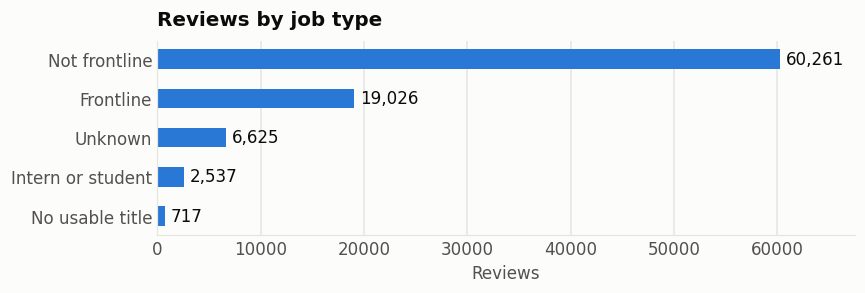

In [10]:
labels = {"no": "Not frontline", "yes": "Frontline", "unknown": "Unknown", "intern_student": "Intern or student", "exclude": "No usable title"}
c = reviews["frontline"].map(labels).value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(c.index, c.values, color=BLUE, height=0.5)
for y, v in enumerate(c.values):
    ax.text(v + c.max() * 0.01, y, f"{v:,}", va="center", color=INK)
ax.set_xlim(0, c.max() * 1.12)
ax.set_xlabel("Reviews")
finish(ax, "Reviews by job type")

## 3. Build the training table

One row per employer per month-end forecast date. An employer is included on a date if it had at least five California reviews in the previous six months. Every input uses only records dated on or before the forecast date, and the answer is whether a layoff notice followed in the next six months.

The finished table is already in the repo. Set `REBUILD = True` to rebuild it from the raw files (about two minutes).

In [11]:
REBUILD = False
if REBUILD:
    !python build_training_table.py
table = pd.read_csv("training_table.csv", parse_dates=["T"])
print(len(table), "rows,", table["T"].nunique(), "forecast dates,", table["key"].nunique(), "employers")
table.groupby("T").agg(employers=("key", "size"), layoff_notice_next_6_months=("y_layoff", "sum")).T

14069 rows, 14 forecast dates, 1774 employers


T,2025-03-31,2025-04-30,2025-05-31,2025-06-30,2025-07-31,2025-08-31,2025-09-30,2025-10-31,2025-11-30,2025-12-31,2026-01-31,2026-02-28,2026-03-31,2026-04-30
employers,743,933,1073,1173,1148,1044,918,926,971,1032,1110,1113,1033,852
layoff_notice_next_6_months,41,44,46,40,40,44,43,41,42,47,44,42,45,43


# 3.1. Data Quality and Manual Validation

To meet the Advanced Track's data validation requirement, we inspect a sample of processed employer observations and compare them against the original WARN and Glassdoor records.

We check:

WARN records: Employer names, notice dates, and affected-worker counts.

Glassdoor records: Employer names, review dates, and employee classifications.

Six-month prediction labels: Whether employers labeled 1 actually filed a WARN notice within the following six months, and whether employers labeled 0 did not.

Company matching: Whether records from different datasets refer to the same employer.

We select four positive and four negative employer-date observations, along with three original records from each dataset.


In [31]:

import pandas as pd
import re
from IPython.display import display

# 1. Select 4 positive and 4 negative examples
samples = []

for label in [1, 0]:
    subset = table[table["y_layoff"] == label]
    samples.append(
        subset.sample(n=min(4, len(subset)), random_state=42)
    )

audit = pd.concat(samples).reset_index(drop=True)

# 2. Define known company-name variations
aliases = {
    "intel": ["intel"],
    "sony pictures entertainment": ["sony pictures"],
    "cisco": ["cisco"],
    "six flags": ["six flags"],
    "konica minolta business solutions": ["konica", "minolta"],
    "staples": ["staples"],
    "fox": ["fox", "twentieth century fox", "21cf"],
    "technicolor": ["technicolor"]
}

# 3. Prepare WARN dates
warn_audit = warn.copy()
warn_audit["notice_date"] = pd.to_datetime(
    warn_audit["notice_date"], errors="coerce"
)

results = []

# 4. Check every selected employer
for _, row in audit.iterrows():

    company = str(row["company"])
    key = str(row["key"])
    T = pd.Timestamp(row["T"])
    end = T + pd.DateOffset(months=6)
    actual_label = int(row["y_layoff"])

    # Use aliases when available
    terms = aliases.get(key, [company])

    pattern = "|".join(re.escape(t) for t in terms)

    matches = warn_audit[
        warn_audit["company"].fillna("").str.contains(
            pattern, case=False, regex=True
        )
    ].copy()

    # Only WARN notices in the next six months
    matches = matches[
        (matches["notice_date"] > T) &
        (matches["notice_date"] <= end)
    ].sort_values("notice_date")

    found = len(matches) > 0

    # Preliminary check, not final manual verification
    if actual_label == 1 and found:
        status = "Positive label supported"
    elif actual_label == 0 and not found:
        status = "Negative label provisionally supported"
    else:
        status = "Investigate"

    results.append({
        "Company": company,
        "Forecast date": T.date(),
        "Label": actual_label,
        "Potential WARN records": len(matches),
        "Status": status
    })

    print("\n" + "=" * 60)
    print("Company:", company)
    print("Expected label:", actual_label)
    print("Forecast window:", T.date(), "to", end.date())
    print("Status:", status)

    if len(matches):
        display(matches[
            ["company", "notice_date", "n_employees", "county"]
        ].head(20))
    else:
        print("No WARN records found under searched names.")

# 5. Display validation summary
validation_results = pd.DataFrame(results)

print("\nMANUAL VALIDATION WORKSHEET")
display(validation_results)

print("\nStatus counts:")
display(validation_results["Status"].value_counts())

print(
    "\nIMPORTANT: Review source records and company aliases "
    "before marking any label as manually verified."
)



Company: Intel Corporation
Expected label: 1
Forecast window: 2025-05-31 to 2025-11-30
Status: Positive label supported


,company,notice_date,n_employees,county
3252,Intel Corporation - Robert Noyce Building,2025-06-18,76,Santa Clara County
3253,Intel Corporation - SC-9,2025-06-18,2,Santa Clara County
3254,Intel Corporation - SC-11,2025-06-18,3,Santa Clara County
3255,Intel Corporation - SC-12,2025-06-18,26,Santa Clara County
3277,Intel Corporation - Robert Noyce,2025-06-25,57,Santa Clara County
3278,Intel Corporation - SC-1 3065 Bowers,2025-06-25,1,Santa Clara County
3279,Intel Corporation - SC-2,2025-06-25,1,Santa Clara County
3280,Intel Corporation - SC-9,2025-06-25,4,Santa Clara County
3281,Intel Corporation - SC-11,2025-06-25,2,Santa Clara County
3282,Intel Corporation,2025-06-25,45,Santa Clara County



Company: Sony Pictures Entertainment
Expected label: 1
Forecast window: 2025-12-31 to 2026-06-30
Status: Positive label supported


,company,notice_date,n_employees,county
4517,Sony Pictures Entertainment Inc.,2026-04-08,111,Los Angeles County
4518,Sony Pictures Entertainment Inc.,2026-04-08,6,Los Angeles County
4519,Sony Pictures Entertainment Inc.,2026-04-08,7,Los Angeles County
4520,Sony Pictures Entertainment Inc.,2026-04-08,9,Los Angeles County



Company: Cisco
Expected label: 1
Forecast window: 2026-04-30 to 2026-10-30
Status: Positive label supported


,company,notice_date,n_employees,county
4841,"Cisco Systems, Inc.",2026-06-16,154,Santa Clara County
4843,"Cisco Systems, Inc.",2026-06-16,81,San Francisco County
4845,"Cisco Systems, Inc.",2026-06-16,236,Santa Clara County
4942,"Yerba Mate Co., LLC - South San Francisco",2026-07-27,1,San Mateo County
4968,"San Francisco Pretrial Diversion Project, Inc.",2026-07-30,82,San Francisco County


... (3 outputs left out)

,Company,Forecast date,Label,Potential WARN records,Status
0,Intel Corporation,2025-05-31,1,29,Positive label supported
1,Sony Pictures Entertainment,2025-12-31,1,4,Positive label supported
2,Cisco,2026-04-30,1,5,Positive label supported
3,Six Flags,2025-04-30,1,4,Positive label supported
4,Konica Minolta Business Solutions,2026-01-31,0,0,Negative label provisionally supported
5,Staples,2025-11-30,0,0,Negative label provisionally supported
6,Fox Corporation,2025-05-31,0,0,Negative label provisionally supported
7,Technicolor,2025-06-30,0,0,Negative label provisionally supported



Status counts:


,count
Status,
Positive label supported,4
Negative label provisionally supported,4



IMPORTANT: Review source records and company aliases before marking any label as manually verified.




To assess the reliability of our training data, we inspected eight sampled employer observations: four positive WARN outcomes and four negative outcomes. We compared the generated labels against historical California WARN records within each employer's six-month forecast window.

#### Validation Results

| Employer | Expected Label | Findings | Status |
|---|---|---|---|
| Intel Corporation | 1 | 29 potential matching WARN records, including confirmed Intel notices | Supported |
| Sony Pictures Entertainment | 1 | 4 Sony Pictures WARN records | Supported |
| Cisco | 1 | 3 matching Cisco Systems records; 2 unrelated search matches excluded | Supported |
| Six Flags | 1 | 4 Six Flags WARN records | Supported |
| Konica Minolta Business Solutions | 0 | No WARN records found under searched names | Provisionally supported |
| Staples | 0 | No WARN records found under searched names | Provisionally supported |
| Fox Corporation | 0 | No WARN records found under searched names | Provisionally supported |
| Technicolor | 0 | No WARN records found under searched names | Provisionally supported |

#### Key Findings

All four positive labels were supported by matching WARN filings within their six-month forecast windows. The four negative labels were consistent with the absence of records under the searched employer names, although additional legal-name and subsidiary checks would be needed for full verification.

Our inspection also revealed that broad company-name searches can return unrelated employers. For example, searching for Cisco also matched company names containing "San Francisco." We excluded these unrelated records when interpreting the validation results.

#### Limitations

This was a small-sample validation of the processed WARN outcome labels. It does not establish that every employer match, Glassdoor feature, or outcome label in the full dataset is correct.

Further checks of Glassdoor review matching and source records would strengthen the validation.

## 4. Train and test the model

For each test date, the model trains only on earlier forecast dates whose six-month outcome was already known by then, and is tested on that date's employers. Training and test rows never overlap in time.

The result files are already in the repo. Set `RETRAIN = True` to rerun the training and testing (about two minutes).

In [12]:
RETRAIN = False
if RETRAIN:
    !python train_model.py
results = pd.read_csv("model_results.csv")
groups = pd.read_csv("model_subgroups.csv")
errors = pd.read_csv("model_errors.csv", parse_dates=["T"])
preds = pd.read_csv("model_predictions.csv", parse_dates=["T"])
main = results[results["model"] == "model: WARN history + review volume"].iloc[0]
chance = main["layoff_cases"] / main["rows"]
print("Test dates:", preds["T"].nunique(), "| employers scored:", int(main["rows"]), "| layoff cases:", int(main["layoff_cases"]), f"| chance rate: {chance:.1%}")
print("Top-10 watchlist:", main["top10_right"], f"right ({main['top10_precision']:.0%})")
print("Ranking score (AUC):", main["auc"])

Test dates: 7 | employers scored: 7037 | layoff cases: 304 | chance rate: 4.3%
Top-10 watchlist: 47 of 70 right (67%)
Ranking score (AUC): 0.856


## 5. Results against the baselines (LOGISTIC MODEL UTILIZED)

The main model uses WARN filing history plus review volume. It is compared with a random guess and two simple rules, and with versions that add review content and stock prices.

BeforeTheNotice uses a Logistic Regression model to predict which California employers are most likely to file a WARN layoff notice within the next six months. The model analyzes factors including historical WARN filings, how recently layoffs occurred, the number of workers previously affected, and recent Glassdoor review volume. It learns patterns from historical data and assigns each employer a risk-ranking score.

In [13]:
results[["model", "top10_right", "top20_right", "top50_right", "top50_recall", "auc", "pr_auc"]]

,model,top10_right,top20_right,top50_right,top50_recall,auc,pr_auc
0,baseline: random guess,5 of 70,6 of 140,11 of 350,0.036,0.514,0.048
1,baseline: most recent WARN filer first,28 of 70,52 of 140,107 of 350,0.352,0.811,0.266
2,baseline: biggest company first,23 of 70,51 of 140,103 of 350,0.339,0.812,0.259
3,model: WARN history + review volume,47 of 70,75 of 140,134 of 350,0.441,0.856,0.359
4,model: + review content,43 of 70,72 of 140,128 of 350,0.421,0.851,0.345
5,model: + review content + stock,40 of 70,71 of 140,130 of 350,0.428,0.839,0.328
6,boosted trees: everything,45 of 70,76 of 140,135 of 350,0.444,0.850,0.385
7,boosted trees: reviews only,38 of 70,66 of 140,108 of 350,0.355,0.800,0.279


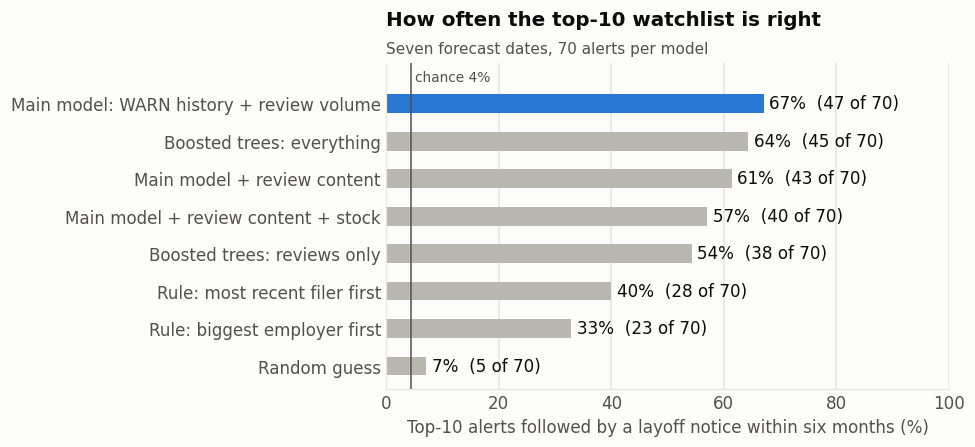

In [14]:
names = {
    "baseline: random guess": "Random guess",
    "baseline: biggest company first": "Rule: biggest employer first",
    "baseline: most recent WARN filer first": "Rule: most recent filer first",
    "model: WARN history + review volume": "Main model: WARN history + review volume",
    "model: + review content": "Main model + review content",
    "model: + review content + stock": "Main model + review content + stock",
    "boosted trees: everything": "Boosted trees: everything",
    "boosted trees: reviews only": "Boosted trees: reviews only",
}
r = results.assign(label=results["model"].map(names)).sort_values("top10_precision")
colors = [BLUE if m == "model: WARN history + review volume" else GRAY for m in r["model"]]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(r["label"], r["top10_precision"] * 100, color=colors, height=0.5)
for y, (v, t) in enumerate(zip(r["top10_precision"] * 100, r["top10_right"])):
    ax.text(v + 1, y, f"{v:.0f}%  ({t})", va="center", color=INK)
ax.axvline(chance * 100, color=MUTED, linewidth=1)
ax.text(chance * 100 + 0.8, len(r) - 0.3, f"chance {chance:.0%}", color=MUTED, fontsize=9, va="center")
ax.set_xlim(0, 100)
ax.set_ylim(-0.6, len(r) + 0.1)
ax.set_xlabel("Top-10 alerts followed by a layoff notice within six months (%)")
finish(ax, "How often the top-10 watchlist is right", "Seven forecast dates, 70 alerts per model")

## 6. Watchlist size: how many alerts are right, and how many layoffs get caught

A longer watchlist is right less often but catches more of the layoffs that happen.

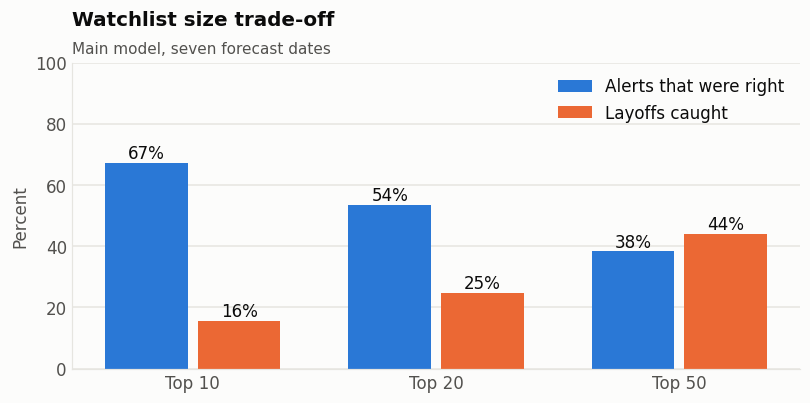

In [15]:
ks = [10, 20, 50]
prec = [main[f"top{k}_precision"] * 100 for k in ks]
rec = [main[f"top{k}_recall"] * 100 for k in ks]
x = np.arange(len(ks))
fig, ax = plt.subplots(figsize=(7.5, 3.8))
b1 = ax.bar(x - 0.19, prec, width=0.34, color=BLUE, label="Alerts that were right")
b2 = ax.bar(x + 0.19, rec, width=0.34, color=ORANGE, label="Layoffs caught")
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5, f"{b.get_height():.0f}%", ha="center", color=INK)
ax.set_xticks(x)
ax.set_xticklabels([f"Top {k}" for k in ks])
ax.set_ylim(0, 100)
ax.set_ylabel("Percent")
ax.legend(frameon=False, loc="upper right")
finish(ax, "Watchlist size trade-off", "Main model, seven forecast dates", grid_axis="y")

## 7. Top-10 watchlist, date by date

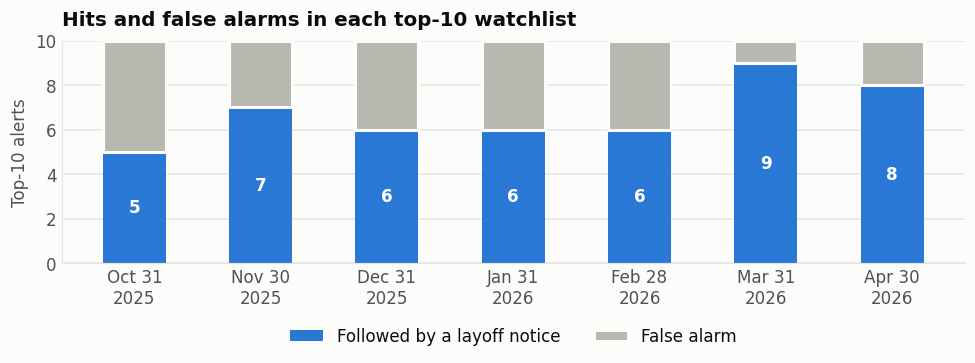

In [16]:
top10 = preds[preds["rank"] <= 10]
hits = top10.groupby("T")["y_layoff"].sum()
d = [t.strftime("%b %d\n%Y") for t in hits.index]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(d, hits.values, color=BLUE, width=0.5, label="Followed by a layoff notice")
ax.bar(d, 10 - hits.values, bottom=hits.values, color=GRAY, width=0.5, label="False alarm", edgecolor=SURFACE, linewidth=2)
for i, v in enumerate(hits.values):
    ax.text(i, v / 2, str(int(v)), ha="center", va="center", color="white", fontweight="bold")
ax.set_ylim(0, 10)
ax.set_ylabel("Top-10 alerts")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
finish(ax, "Hits and false alarms in each top-10 watchlist", grid_axis="y")

In [17]:
latest = preds["T"].max()
print("Top-10 watchlist as of", latest.date())
top10[top10["T"] == latest][["rank", "company", "score", "y_layoff"]].rename(columns={"y_layoff": "layoff_notice_followed"}).reset_index(drop=True)

Top-10 watchlist as of 2026-04-30


,rank,company,score,layoff_notice_followed
0,1,Oracle,0.997894,1
1,2,Meta,0.997201,1
2,3,Google,0.996028,0
3,4,University of Southern California,0.993890,1
4,5,Qualcomm,0.991673,0
5,6,Intel Corporation,0.989811,1
6,7,Genentech,0.984932,1
7,8,Apple,0.976298,1
8,9,Gilead Sciences,0.971670,1
9,10,Salesforce,0.961044,1


## 8. Fairness: who the model works for

The same test results, split by group. The ranking score (AUC) is 0.5 for a coin flip and 1.0 for a perfect ranking.

In [ ]:
groups

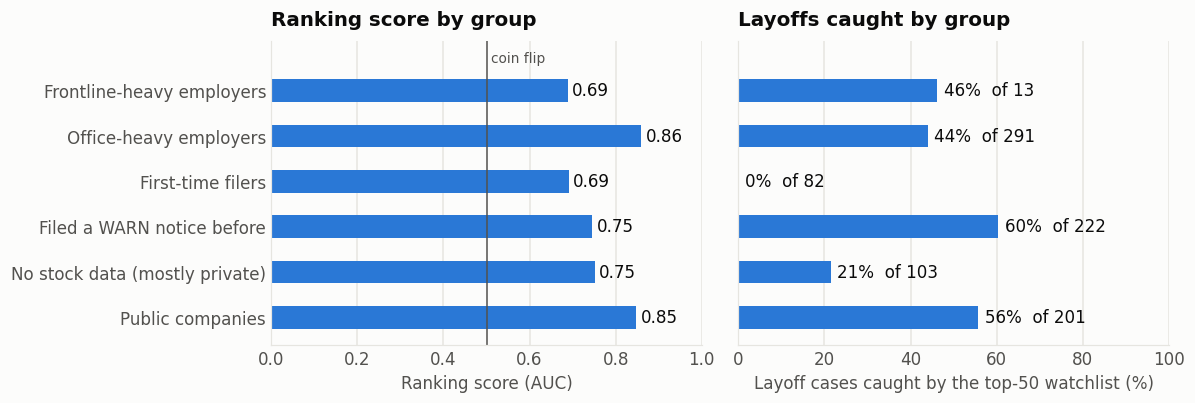

In [18]:
order = [("frontline", "frontline-heavy", "Frontline-heavy employers"), ("frontline", "office-heavy", "Office-heavy employers"),
         ("history", "first-time", "First-time filers"), ("history", "filed before", "Filed a WARN notice before"),
         ("stock", "no stock data", "No stock data (mostly private)"), ("stock", "public (has stock)", "Public companies")]
g = pd.DataFrame([{"label": lab, **groups[(groups["breakdown"] == b) & (groups["group"] == grp)].iloc[0].to_dict()} for b, grp, lab in order])[::-1]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
ax = axes[0]
ax.barh(g["label"], g["auc"], color=BLUE, height=0.5)
for y, v in enumerate(g["auc"]):
    ax.text(v + 0.01, y, f"{v:.2f}", va="center", color=INK)
ax.axvline(0.5, color=MUTED, linewidth=1)
ax.text(0.51, len(g) - 0.3, "coin flip", color=MUTED, fontsize=9, va="center")
ax.set_xlim(0, 1)
ax.set_ylim(-0.6, len(g) + 0.1)
ax.set_xlabel("Ranking score (AUC)")
ax.set_title("Ranking score by group", pad=10)
ax.grid(axis="x", color=GRID, linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)

ax = axes[1]
ax.barh(g["label"], g["caught_in_top50"] * 100, color=BLUE, height=0.5)
for y, (v, n) in enumerate(zip(g["caught_in_top50"] * 100, g["layoff_cases"])):
    ax.text(v + 1.5, y, f"{v:.0f}%  of {int(n)}", va="center", color=INK)
ax.set_xlim(0, 100)
ax.set_xlabel("Layoff cases caught by the top-50 watchlist (%)")
ax.set_title("Layoffs caught by group", pad=10)
ax.grid(axis="x", color=GRID, linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
plt.tight_layout()
plt.show()

## 9. Where the model fails

False alarms are employers in a top-10 watchlist with no layoff notice in the next six months. Missed layoffs are employers ranked below 50 that did get one.

In [19]:
fa = errors[errors["error"] == "false alarm"]
print(len(fa), "false alarms in the top-10 watchlists")
fa[["T", "company", "rank", "w_days_since", "w_n_12"]].rename(columns={"w_days_since": "days_since_last_notice", "w_n_12": "notices_past_12_months"}).reset_index(drop=True)

23 false alarms in the top-10 watchlists


,T,company,rank,days_since_last_notice,notices_past_12_months
0,2025-10-31,Applied Materials,4,7.0,15.0
1,2025-10-31,AT&T,5,231.0,5.0
2,2025-10-31,Cruise,3,30.0,22.0
3,2025-10-31,Disneyland Resort,8,3.0,1.0
4,2025-10-31,Hewlett Packard Enterprise | HPE,6,1.0,2.0
5,2025-11-30,Chevron,7,47.0,7.0
6,2025-11-30,Cruise,1,60.0,22.0
7,2025-11-30,Kaiser Permanente,2,45.0,139.0
8,2025-12-31,Cruise,3,91.0,22.0
9,2025-12-31,Illumina,9,8.0,6.0


In [20]:
missed = errors[errors["error"] == "missed layoff"]
print(len(missed), "layoff cases ranked below 50. Largest by workers affected:")
missed.sort_values("workers_next6", ascending=False)[["T", "company", "rank", "workers_next6", "w_days_since"]].rename(columns={"workers_next6": "workers_affected", "w_days_since": "days_since_last_notice"}).head(15).reset_index(drop=True)

170 layoff cases ranked below 50. Largest by workers affected:


,T,company,rank,workers_affected,days_since_last_notice
0,2025-12-31,Amazon,70,4880.0,63.0
1,2026-04-30,Netflix,158,553.0,2000.0
2,2025-12-31,eBay,73,469.0,699.0
3,2026-01-31,eBay,78,469.0,730.0
4,2025-10-31,eBay,75,469.0,638.0
5,2025-11-30,eBay,80,469.0,668.0
6,2026-04-30,Uber,143,463.0,2000.0
7,2026-03-31,Uber,141,463.0,2000.0
8,2026-04-30,ServiceNow,132,424.0,2000.0
9,2026-01-31,ServiceNow,135,404.0,2000.0


## 10. Look up a company

In [ ]:
def lookup(name):
    d = preds[preds["company"].str.contains(name, case=False, na=False)]
    return d[["T", "company", "rank", "score", "y_layoff"]].rename(columns={"y_layoff": "layoff_notice_followed"}).sort_values(["company", "T"]).reset_index(drop=True)


lookup("Intel")

## 11. Limitations

- **It is a repeat-filer model.** Every employer in the top-10 watchlists had filed a WARN notice before. It does not catch first-time filers.
- **Only large employers are covered.** California's WARN rule applies to employers with 75 or more workers and layoffs of 50 or more. Small-business closures, individual firings, and cut hours never produce a notice.
- **Frontline workers get less warning.** The ranking score is lower for frontline-heavy employers, and there are few such cases to test on.
- **Review content and stock prices did not improve the model.** Ratings, outlook answers, layoff keywords, and stock returns were tested and left out of the main model.
- **Company name matching is incomplete.** WARN notices are filed under legal names, and some are not linked to their Glassdoor page.
- **Glassdoor reviewers are not representative.** They skew toward office workers at large companies, and toward people with strong opinions.
- **A score is a ranking, not a probability.** A false alarm about a real employer can cause harm, so results should be used for preparedness and outreach planning, not as a prediction about any one company.

## **12. Future Predictions**

-We apply our trained model to the latest available employer data to identify companies with elevated risk of filing a California WARN notice within the next six months.

-Our latest watchlist contains 604 employers, ranked using historical WARN filing activity and Glassdoor review volume.

-This is future data however, our predictions cannot be evaluated yet

-


-

In [25]:

import pandas as pd

# Load the latest watchlist directly from GitHub
url = "https://raw.githubusercontent.com/Sriram-Karthik17/BeforeTheNotice/main/watchlist.csv"

watchlist = pd.read_csv(url)

print("Watchlist loaded successfully!")
print("Total companies:", len(watchlist))



Watchlist loaded successfully!
Total companies: 604


In [26]:

watchlist["as_of"] = pd.to_datetime(watchlist["as_of"])
watchlist = watchlist.sort_values("rank")

snapshot = watchlist["as_of"].max()
forecast_end = snapshot + pd.DateOffset(months=6)

print("Prediction date:", snapshot.date())
print("Forecast through:", forecast_end.date())
print("Total employers scored:", len(watchlist))

display(
    watchlist[
        ["rank", "company", "risk_level",
         "risk_score", "notices_past_year",
         "sector", "reason"]
    ].head(20)
)

Prediction date: 2026-11-09
Forecast through: 2027-05-09
Total employers scored: 604


,rank,company,risk_level,risk_score,notices_past_year,sector,reason
0,1,ServiceNow,High,0.993,8,professional,"8 WARN notices in the past year, most recent 5..."
1,2,Meta,High,0.991,16,professional,"16 WARN notices in the past year, most recent ..."
2,3,City National Bank,High,0.986,10,professional,"10 WARN notices in the past year, most recent ..."
3,4,Apple,High,0.984,4,professional,"4 WARN notices in the past year, most recent 8..."
4,5,Oracle,High,0.981,7,professional,"7 WARN notices in the past year, most recent 5..."
5,6,Walmart,High,0.974,9,professional,"9 WARN notices in the past year, most recent 1..."
6,7,Walt Disney Company,High,0.974,1,professional,"1 WARN notice in the past year, most recent 13..."
7,8,Intel Corporation,High,0.974,14,professional,"14 WARN notices in the past year, most recent ..."
8,9,Uber,High,0.973,11,professional,"11 WARN notices in the past year, most recent ..."
9,10,Salesforce,High,0.969,3,professional,"3 WARN notices in the past year, most recent 9..."


#12 FUTURE JOB WARN WATCHLIST VISUALIZATION

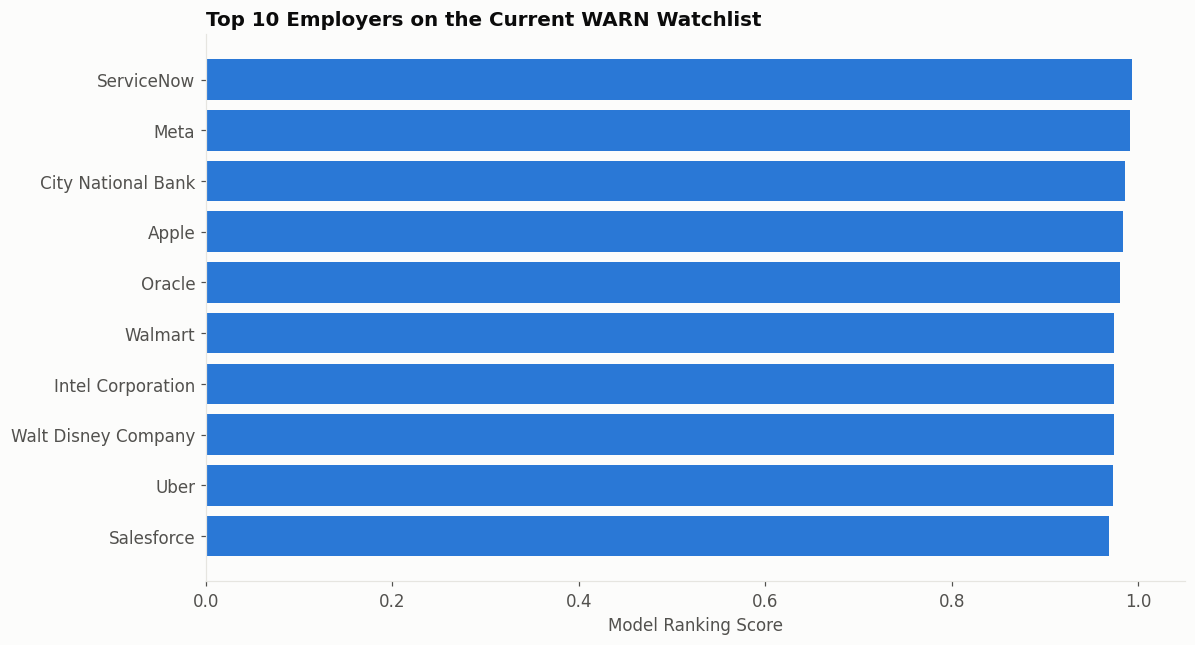

In [27]:

top10_future = watchlist.head(10).sort_values("risk_score")

plt.figure(figsize=(11, 6))
plt.barh(
    top10_future["company"],
    top10_future["risk_score"],
    color="#2a78d6"
)

plt.xlabel("Model Ranking Score")
plt.title("Top 10 Employers on the Current WARN Watchlist")
plt.xlim(0, 1.05)
plt.tight_layout()
plt.show()
